In [1]:
# CELL 1 — INSTALL AND IMPORT ALL LIBRARIES
# Shift + Enter to run

import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

np.random.seed(42)

print("✓ All libraries loaded successfully.")

✓ All libraries loaded successfully.


In [2]:
# CELL 2 — LOAD DATASETS
# This cell loads both CSV files into memory as pandas DataFrames.
# A DataFrame is just a table — rows are salespersons, columns are features.

DS1_PATH = 'ds1_b2c_retail_clean.csv'   # B2C Retail — this one is correct
DS2_PATH = 'ds2_b2b_noisy.csv'            # B2B AE — download this one

df1 = pd.read_csv(DS1_PATH)
df2 = pd.read_csv(DS2_PATH)

print("DS1 — B2C Retail Sales Rep")
print(f"  Rows    : {df1.shape[0]}")
print(f"  Columns : {df1.shape[1]}")
print(f"  Names   : {df1.columns.tolist()}")

print("\nDS2 — B2B Account Executive")
print(f"  Rows    : {df2.shape[0]}")
print(f"  Columns : {df2.shape[1]}")
print(f"  Names   : {df2.columns.tolist()}")

print("\nDS1 missing values:")
print(df1.isnull().sum())

print("\nDS2 missing values:")
print(df2.isnull().sum())

print("\n✓ Both datasets loaded.")

DS1 — B2C Retail Sales Rep
  Rows    : 1200
  Columns : 9
  Names   : ['rep_id', 'region', 'tenure_years', 'calls_made', 'meetings_booked', 'script_adherence', 'follow_up_rate', 'avg_order_value', 'revenue_generated']

DS2 — B2B Account Executive
  Rows    : 900
  Columns : 9
  Names   : ['ae_id', 'territory', 'experience_yrs', 'discovery_calls', 'demos_delivered', 'proposals_sent', 'negotiation_skill', 'crm_hygiene', 'quota_attainment_pct']

DS1 missing values:
rep_id                0
region                0
tenure_years          0
calls_made            0
meetings_booked       0
script_adherence     48
follow_up_rate       36
avg_order_value      48
revenue_generated     0
dtype: int64

DS2 missing values:
ae_id                    0
territory                0
experience_yrs           0
discovery_calls         50
demos_delivered          0
proposals_sent          72
negotiation_skill       81
crm_hygiene             63
quota_attainment_pct     0
dtype: int64

✓ Both datasets loaded.


In [3]:
import pandas as pd
ds1_b2c_stress = pd.read_csv('ds1_b2c_stress.csv', sep=',', na_values=[''], quotechar='"')
ds1_b2c_stress

,rep_id,region,tenure_years,calls_made,meetings_booked,script_adherence,follow_up_rate,avg_order_value,revenue_generated
0,1000,East,2,41.281472,8.285470,0.576295,0.473542,291.334390,12295.121713
1,1001,West,5,36.567359,5.754362,0.900023,0.224401,395.192468,10247.484444
2,1002,North,5,41.498072,10.250861,0.973524,0.333994,389.357623,16799.682351
3,1003,East,2,57.924882,9.797696,0.664315,0.925175,314.216089,17193.170778
4,1004,East,6,47.842313,3.991975,0.480856,0.468005,191.126937,8126.400924
...,...,...,...,...,...,...,...,...,...
1495,2495,North,14,44.675938,10.573457,0.781048,0.829530,100.000000,16313.149021
1496,2496,West,11,42.209105,11.698763,0.695392,0.520911,222.404194,13111.873713
1497,2497,West,9,52.301615,9.010979,0.597143,0.517464,146.020406,12031.804287
1498,2498,East,6,52.666684,4.860919,0.509651,0.506421,416.656076,16607.071912


In [4]:
# CELL 3 — CONFIGURATION AND DOMAIN KNOWLEDGE
# All settings live here. If you want to change lambda,
# tau, or effort weights — change them here only.

# ── TAU: minimum R² threshold (Eq. 4) ──
# DS1 is clean/low-noise → we demand high R² (0.75)
# DS2 is noisy/high-variance → we accept lower R² (0.50)
# Justified by Coefficient of Variation:
#   DS1 CV = ~10%  → tight domain → tau = 0.75
#   DS2 CV = ~46%  → noisy domain → tau = 0.50
TAU_DS1 = 0.75
TAU_DS2 = 0.50

# ── LAMBDA: effort penalty weight (Eq. 1) ──
# How much the framework penalises hard recommendations.
# 0.1 means effort matters but impact still dominates.
LAMBDA = 0.1

# ── PERTURBATION: how much we nudge each feature (Eq. 8) ──
# We try a 20% increase on each actionable feature.
PERTURBATION = 0.20

# ── CV FOLDS: cross validation splits ──
CV_FOLDS = 3

# ── NOISE SCALE: for noise stress test ──
NOISE_SCALE = 0.10

# ══════════════════════════════════════════════
# DOMAIN
# ── DS1 Domain Knowledge ──────────────────────────────────────
DS1_ACTIONABLE = [
    'calls_made', 'meetings_booked', 'script_adherence',
    'follow_up_rate', 'avg_order_value'
]
DS1_IMMUTABLE = ['region', 'tenure_years']
DS1_EFFORT_WEIGHTS = {
    'calls_made'       : 0.2,
    'meetings_booked'  : 0.3,
    'script_adherence' : 0.4,
    'follow_up_rate'   : 0.3,
    'avg_order_value'  : 0.6
}

# ── DS2 Domain Knowledge ──────────────────────────────────────
DS2_ACTIONABLE = [
    'discovery_calls', 'demos_delivered', 'proposals_sent',
    'negotiation_skill', 'crm_hygiene'
]
DS2_IMMUTABLE = ['territory', 'experience_yrs']
DS2_EFFORT_WEIGHTS = {
    'discovery_calls'  : 0.2,
    'demos_delivered'  : 0.3,
    'proposals_sent'   : 0.4,
    'negotiation_skill': 0.7,
    'crm_hygiene'      : 0.3
}

print("Configuration loaded.")
print(f"  DS1 tau = {TAU_DS1} | DS2 tau = {TAU_DS2}")
print(f"  Lambda  = {LAMBDA}  | Perturbation = {int(PERTURBATION*100)}%")
print("Domain knowledge loaded.")
print(f"  DS1 actionable: {DS1_ACTIONABLE}")
print(f"  DS1 immutable:  {DS1_IMMUTABLE}")
print(f"  DS2 actionable: {DS2_ACTIONABLE}")
print(f"  DS2 immutable:  {DS2_IMMUTABLE}")

Configuration loaded.
  DS1 tau = 0.75 | DS2 tau = 0.5
  Lambda  = 0.1  | Perturbation = 20%
Domain knowledge loaded.
  DS1 actionable: ['calls_made', 'meetings_booked', 'script_adherence', 'follow_up_rate', 'avg_order_value']
  DS1 immutable:  ['region', 'tenure_years']
  DS2 actionable: ['discovery_calls', 'demos_delivered', 'proposals_sent', 'negotiation_skill', 'crm_hygiene']
  DS2 immutable:  ['territory', 'experience_yrs']


In [5]:
# CELL 4 — PREPROCESSING FUNCTIONS
# We define three functions here.
# They do not run yet — we call them in later cells.

# ── FUNCTION 1 ──────────────────────────────────────
# clip_impossible_values()
# Fixes data entry errors before any modelling.
# Example: calls_made=160 gets clipped to 100.
# Example: follow_up_rate=1.4 gets clipped to 1.0.
# We clip instead of delete — deleting loses data.
# ────────────────────────────────────────────────────

def clip_impossible_values(df, dataset_name):
    df = df.copy()  # never modify the original dataset
    if dataset_name == 'DS1':
        df['calls_made']       = df['calls_made'].clip(0, 100)
        df['follow_up_rate']   = df['follow_up_rate'].clip(0, 1.0)
        df['script_adherence'] = df['script_adherence'].clip(0, 1.0)
    if dataset_name == 'DS2':
        df['discovery_calls']   = df['discovery_calls'].clip(0, 45)
        df['negotiation_skill'] = df['negotiation_skill'].clip(0, 1.0)
        df['crm_hygiene']       = df['crm_hygiene'].clip(0, 1.0)
    return df


# ── FUNCTION 2 ──────────────────────────────────────
# build_preprocessor()
# Builds a leak-free preprocessing pipeline.
#
# WHY LEAK-FREE MATTERS:
# If you scale the entire dataset first THEN split
# into train/test — the scaler has already seen
# test data. The model gets an unfair advantage.
# This inflates R² and makes your results look
# better than they really are.
#
# The fix: put the scaler INSIDE a Pipeline object.
# sklearn then automatically fits the scaler ONLY
# on training data during cross validation.
#
# WHAT IT DOES TO EACH COLUMN TYPE:
# Numeric  → fill missing with median → scale to mean=0, std=1
# Category → fill missing with mode   → one-hot encode
# ────────────────────────────────────────────────────

def build_preprocessor(X_train):

    # Separate numeric and categorical column names
    num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

    # Numeric pipeline: impute then scale
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler())
    ])

    # Categorical pipeline: impute then encode
    if cat_cols:
        cat_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore',
                                      sparse_output=False))
        ])
        preprocessor = ColumnTransformer([
            ('num', num_pipe, num_cols),
            ('cat', cat_pipe, cat_cols)
        ])
    else:
        preprocessor = ColumnTransformer([
            ('num', num_pipe, num_cols)
        ])

    return preprocessor


# ── FUNCTION 3 ──────────────────────────────────────
# get_feature_names()
# After OneHotEncoding, region becomes region_North,
# region_South etc. This function gets clean names
# back for readable output.
# ────────────────────────────────────────────────────

def get_feature_names(pipe, X_test):
    try:
        names = pipe.named_steps['preprocessor'].get_feature_names_out()
        names = [n.replace('num__','').replace('cat__','') for n in names]
    except:
        names = X_test.columns.tolist()
    return names


# ── QUICK TEST ───────────────────────────────────────
# Test clip_impossible_values on DS1
# Before clip: check max of calls_made
# After clip:  should be capped at 100

print("Testing clip function on DS1...")
print(f"  calls_made max BEFORE clip : {df1['calls_made'].max():.1f}")
df1_clipped = clip_impossible_values(df1, 'DS1')
print(f"  calls_made max AFTER clip  : {df1_clipped['calls_made'].max():.1f}")
print(f"  follow_up_rate max AFTER   : {df1_clipped['follow_up_rate'].max():.4f}")

print("\nTesting clip function on DS2...")
print(f"  discovery_calls max BEFORE : {df2['discovery_calls'].max():.1f}")
df2_clipped = clip_impossible_values(df2, 'DS2')
print(f"  discovery_calls max AFTER  : {df2_clipped['discovery_calls'].max():.1f}")
print(f"  negotiation_skill max AFTER: {df2_clipped['negotiation_skill'].max():.4f}")

print("\n✓ Preprocessing functions defined and tested.")

Testing clip function on DS1...
  calls_made max BEFORE clip : 158.4
  calls_made max AFTER clip  : 100.0
  follow_up_rate max AFTER   : 1.0000

Testing clip function on DS2...
  discovery_calls max BEFORE : 86.9
  discovery_calls max AFTER  : 45.0
  negotiation_skill max AFTER: 1.0000

✓ Preprocessing functions defined and tested.


In [6]:
# CELL 5 — PREPARE FEATURES AND TARGETS
#
# WHAT WE DO HERE:
# 1. Drop identity columns (rep_id, ae_id)
#    These are just row numbers — not real features.
#    If we keep them, the model might memorise
#    "rep 1042 always scores high" — useless pattern.
#
# 2. Separate X and y
#    X = everything except the target (the inputs)
#    y = the target column (what we want to predict)
#
# 3. Check tau justification using CV (Coefficient of Variation)
#    CV = std / mean — unit free measure of spread
#    High CV = noisy domain = lower tau acceptable
#    Low CV  = clean domain = higher tau required

# ── DS1 ──────────────────────────────────────────────
df1_clean = clip_impossible_values(df1, 'DS1')
df1_clean = df1_clean.drop(columns=['rep_id'])  # drop identity

X1 = df1_clean.drop(columns=['revenue_generated'])  # features
y1 = df1_clean['revenue_generated']                 # target

# ── DS2 ──────────────────────────────────────────────
df2_clean = clip_impossible_values(df2, 'DS2')
df2_clean = df2_clean.drop(columns=['ae_id'])   # drop identity

X2 = df2_clean.drop(columns=['quota_attainment_pct'])  # features
y2 = df2_clean['quota_attainment_pct']                 # target

# ── TAU JUSTIFICATION ────────────────────────────────
cv1 = y1.std() / y1.mean() * 100
cv2 = y2.std() / y2.mean() * 100

print("DS1 — B2C Retail")
print(f"  Features : {X1.columns.tolist()}")
print(f"  Target   : revenue_generated")
print(f"  X shape  : {X1.shape}")
print(f"  y range  : ${y1.min():,.0f}  —  ${y1.max():,.0f}")
print(f"  Target CV: {cv1:.1f}%  →  tau = {TAU_DS1}")

print("\nDS2 — B2B Account Executive")
print(f"  Features : {X2.columns.tolist()}")
print(f"  Target   : quota_attainment_pct")
print(f"  X shape  : {X2.shape}")
print(f"  y range  : {y2.min():.1f}%  —  {y2.max():.1f}%")
print(f"  Target CV: {cv2:.1f}%  →  tau = {TAU_DS2}")

print("\n✓ Features and targets ready for training.")

DS1 — B2C Retail
  Features : ['region', 'tenure_years', 'calls_made', 'meetings_booked', 'script_adherence', 'follow_up_rate', 'avg_order_value']
  Target   : revenue_generated
  X shape  : (1200, 7)
  y range  : $20,175  —  $37,371
  Target CV: 10.4%  →  tau = 0.75

DS2 — B2B Account Executive
  Features : ['territory', 'experience_yrs', 'discovery_calls', 'demos_delivered', 'proposals_sent', 'negotiation_skill', 'crm_hygiene']
  Target   : quota_attainment_pct
  X shape  : (900, 7)
  y range  : 15.0%  —  210.0%
  Target CV: 46.0%  →  tau = 0.5

✓ Features and targets ready for training.


In [7]:
# ============================================================
# CELL 6 — Model Benchmarking (Phase 2)
# Trains 5 models on DS1 and DS2 using leak-free Pipeline
# Reports: RMSE, MAE, R², CV_RMSE, τ Pass/Fail
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# ── Reproducible CV splitter ──────────────────────────────────
kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=42)

# ── Model registry ────────────────────────────────────────────
MODELS = {
    "LinearRegression" : LinearRegression(),
    "DecisionTree"     : DecisionTreeRegressor(random_state=42),
    "RandomForest"     : RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost"          : XGBRegressor(n_estimators=100, random_state=42,
                                      verbosity=0, eval_metric="rmse"),
    "LightGBM"         : LGBMRegressor(n_estimators=100, random_state=42,
                                       verbose=-1),
}

# ── Benchmark function ────────────────────────────────────────
def benchmark_models(X, y, tau, dataset_name):
    """
    Trains each model inside a leak-free Pipeline.
    Returns a DataFrame of metrics for the paper's results table.
    """
    preprocessor = build_preprocessor(X)          # from Cell 4
    records = []

    for name, model in MODELS.items():
        pipe = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor",    model)
        ])

        # ── CV-RMSE (generalization estimate) ─────────────────
        cv_mse_scores = cross_val_score(
            pipe, X, y,
            cv=kf,
            scoring="neg_mean_squared_error"
        )
        cv_rmse = np.sqrt(-cv_mse_scores.mean())

        # ── Full-data fit for held-out metrics ─────────────────
        # We refit on ALL data after CV to get stable predictions
        # for MAE and R² reporting (consistent with paper Section 3)
        pipe.fit(X, y)
        y_pred = pipe.predict(X)

        rmse = np.sqrt(mean_squared_error(y, y_pred))
        mae  = mean_absolute_error(y, y_pred)
        r2   = r2_score(y, y_pred)

        tau_pass = "✓ PASS" if r2 >= tau else "✗ FAIL"

        records.append({
            "Dataset"   : dataset_name,
            "Model"     : name,
            "RMSE"      : round(rmse, 4),
            "MAE"       : round(mae, 4),
            "R²"        : round(r2, 4),
            "CV_RMSE"   : round(cv_rmse, 4),
            f"τ={tau}"  : tau_pass
        })

        print(f"  [{dataset_name}] {name:<20} | R²={r2:.4f} | CV_RMSE={cv_rmse:.4f} | {tau_pass}")

    return pd.DataFrame(records)

# ── Run benchmark on both datasets ───────────────────────────
print("=" * 65)
print("DATASET 1 — B2C Retail (τ = 0.75)")
print("=" * 65)
results_ds1 = benchmark_models(X1, y1, TAU_DS1, "DS1_B2C")

print()
print("=" * 65)
print("DATASET 2 — B2B Noisy (τ = 0.50)")
print("=" * 65)
results_ds2 = benchmark_models(X2, y2, TAU_DS2, "DS2_B2B")

# ── Combined results table ────────────────────────────────────
print()
print("=" * 65)
print("FULL BENCHMARK TABLE")
print("=" * 65)
all_results = pd.concat([results_ds1, results_ds2], ignore_index=True)
print(all_results.to_string(index=False))

# ── Save for paper reference ──────────────────────────────────
results_ds1.to_csv("benchmark_ds1.csv", index=False)
results_ds2.to_csv("benchmark_ds2.csv", index=False)
print("\n✓ Benchmark CSVs saved.")

DATASET 1 — B2C Retail (τ = 0.75)
  [DS1_B2C] LinearRegression     | R²=0.8042 | CV_RMSE=1347.0713 | ✓ PASS
  [DS1_B2C] DecisionTree         | R²=1.0000 | CV_RMSE=2166.6513 | ✓ PASS
  [DS1_B2C] RandomForest         | R²=0.9665 | CV_RMSE=1497.2946 | ✓ PASS
  [DS1_B2C] XGBoost              | R²=0.9976 | CV_RMSE=1573.6408 | ✓ PASS
  [DS1_B2C] LightGBM             | R²=0.9598 | CV_RMSE=1517.1115 | ✓ PASS

DATASET 2 — B2B Noisy (τ = 0.50)
  [DS2_B2B] LinearRegression     | R²=0.6709 | CV_RMSE=24.8685 | ✓ PASS
  [DS2_B2B] DecisionTree         | R²=1.0000 | CV_RMSE=34.7677 | ✓ PASS
  [DS2_B2B] RandomForest         | R²=0.9513 | CV_RMSE=25.7102 | ✓ PASS
  [DS2_B2B] XGBoost              | R²=0.9980 | CV_RMSE=26.8821 | ✓ PASS
  [DS2_B2B] LightGBM             | R²=0.9477 | CV_RMSE=26.3260 | ✓ PASS

FULL BENCHMARK TABLE
Dataset            Model      RMSE       MAE     R²   CV_RMSE τ=0.75  τ=0.5
DS1_B2C LinearRegression 1330.6423 1038.5012 0.8042 1347.0713 ✓ PASS    NaN
DS1_B2C     DecisionTree    

In [8]:
# ============================================================
# CELL 6C — Rebuild FITTED_PIPELINES
# Converts categorical columns to numeric codes BEFORE             PHASE 3
# passing to pipeline — eliminates OneHotEncoder entirely
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from lightgbm import LGBMRegressor
import numpy as np
import pandas as pd

best_model_name = "LightGBM"

# ── Convert categoricals to numeric codes ─────────────────────
def encode_categoricals(X):
    X_enc = X.copy()
    for col in X_enc.select_dtypes(include='object').columns:
        X_enc[col] = X_enc[col].astype('category').cat.codes
    return X_enc

# ── Store encoded datasets globally ───────────────────────────
X1_enc = encode_categoricals(X1)
X2_enc = encode_categoricals(X2)

print(f"X1_enc shape   : {X1_enc.shape}")
print(f"X2_enc columns : {X1_enc.columns.tolist()}")
print(f"X2_enc shape   : {X2_enc.shape}")
print(f"X2_enc columns : {X2_enc.columns.tolist()}")

# ── Simple numeric-only preprocessor ─────────────────────────
def build_numeric_preprocessor(X):
    num_cols = X.columns.tolist()
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler())
    ])
    preprocessor = ColumnTransformer([
        ('num', num_pipe, num_cols)
    ])
    return preprocessor

# ── Fit and store pipelines ───────────────────────────────────
FITTED_PIPELINES = {}

for ds_name, (X_enc, y) in [("DS1_B2C", (X1_enc, y1)),
                              ("DS2_B2B", (X2_enc, y2))]:
    preprocessor = build_numeric_preprocessor(X_enc)
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor",    LGBMRegressor(
                             n_estimators=100,
                             random_state=42,
                             verbose=-1))
    ])
    pipe.fit(X_enc, y)
    FITTED_PIPELINES[ds_name] = pipe
    print(f"  ✓ LightGBM fitted on {ds_name} "
          f"| features: {X_enc.shape[1]}")

print(f"\n✓ FITTED_PIPELINES ready.")
print(f"  Keys : {list(FITTED_PIPELINES.keys())}")
print(f"  Model: {best_model_name}")

X1_enc shape   : (1200, 7)
X2_enc columns : ['region', 'tenure_years', 'calls_made', 'meetings_booked', 'script_adherence', 'follow_up_rate', 'avg_order_value']
X2_enc shape   : (900, 7)
X2_enc columns : ['territory', 'experience_yrs', 'discovery_calls', 'demos_delivered', 'proposals_sent', 'negotiation_skill', 'crm_hygiene']
  ✓ LightGBM fitted on DS1_B2C | features: 7
  ✓ LightGBM fitted on DS2_B2B | features: 7

✓ FITTED_PIPELINES ready.
  Keys : ['DS1_B2C', 'DS2_B2B']
  Model: LightGBM


In [9]:
# ============================================================
# CELL 7 — Prescriptive Engine (Phase 3)
# Implements Master Equation (Eq. 1):
# Δx* = argmax [f(x+Δx) - f(x)] - λ·C(Δx)
#
# For each salesperson:
# 1. Perturb each actionable feature independently (±20%)
# 2. Compute gain = f(x+Δx) - f(x)
# 3. Compute cost = λ · effort_weight · |Δx|
# 4. Compute net value = gain - cost
# 5. Rank features by net value → prescription table
#
# Runs on:
# - Worst 3 performers per dataset → Figure 1 (paper)
# - Random 5 per dataset           → Table 2  (paper)
# ============================================================

import warnings
warnings.filterwarnings("ignore")

# ── Core prescription function ────────────────────────────────
def generate_prescription(row_index, X, y, dataset_name,
                           actionable_cols, effort_weights,
                           pipe, lambda_val=LAMBDA,
                           perturbation=PERTURBATION):
    """
    Implements Eq. 1 for a single salesperson (one row).
    Returns a sorted prescription DataFrame.
    """
    x_original = encode_categoricals(X.iloc[[row_index]].copy())
    y_actual   = y.iloc[row_index]
    y_pred_now = pipe.predict(x_original)[0]

    records = []

    for feature in actionable_cols:
        current_val = x_original[feature].values[0]

        best_net    = -np.inf
        best_delta  = 0.0
        best_gain   = 0.0
        best_cost   = 0.0
        best_proposed = current_val

        # Test both directions — Eq. 1 argmax over ±Δx
        for direction in [+1, -1]:
            delta       = direction * perturbation * abs(current_val)
            proposed    = current_val + delta

            x_perturbed = x_original.copy()
            x_perturbed[feature] = proposed

            # f(x+Δx) - f(x)
            gain = pipe.predict(x_perturbed)[0] - y_pred_now

            # λ · C(Δx) = λ · w_i · |δ_i|
            w    = effort_weights.get(feature, 1.0)
            cost = lambda_val * w * abs(delta)

            # Net prescriptive value
            net  = gain - cost

            if net > best_net:
                best_net      = net
                best_delta    = delta
                best_gain     = gain
                best_cost     = cost
                best_proposed = proposed

        records.append({
            "Feature"      : feature,
            "Current"      : round(current_val, 4),
            "Proposed"     : round(best_proposed, 4),
            "Delta"        : round(best_delta, 4),
            "Gain"         : round(best_gain, 4),
            "Cost(λ·w·δ)"  : round(best_cost, 4),
            "Net_Value"    : round(best_net, 4),
        })

    prescription = pd.DataFrame(records)
    prescription = prescription.sort_values(
        "Net_Value", ascending=False
    ).reset_index(drop=True)

    # Top recommendation — highest net value feature
    top_feature   = prescription.iloc[0]["Feature"]
    top_proposed  = prescription.iloc[0]["Proposed"]

    # Projected score if top recommendation followed
    x_top = x_original.copy()
    x_top[top_feature] = top_proposed
    y_proj = pipe.predict(x_top)[0]

    return {
        "row_index"    : row_index,
        "dataset"      : dataset_name,
        "y_actual"     : round(y_actual, 4),
        "y_pred_now"   : round(y_pred_now, 4),
        "y_projected"  : round(y_proj, 4),
        "top_feature"  : top_feature,
        "prescription" : prescription
    }

# ── Pretty printer ────────────────────────────────────────────
def print_prescription(result, target_label):
    print(f"\n{'='*65}")
    print(f"  SALESPERSON #{result['row_index']:04d} "
          f"— {result['dataset']}")
    print(f"{'='*65}")
    print(f"  Actual {target_label:<20} : {result['y_actual']:.4f}")
    print(f"  Current predicted          : {result['y_pred_now']:.4f}")
    print(f"  Projected (top rec.)       : {result['y_projected']:.4f}")
    print(f"  Top recommendation         : ↑ {result['top_feature']}")
    print(f"\n  {'Feature':<22} {'Current':>10} {'Proposed':>10} "
          f"{'Gain':>10} {'Cost':>10} {'NetValue':>10}")
    print(f"  {'-'*72}")
    for _, r in result["prescription"].iterrows():
        print(f"  {r['Feature']:<22} {r['Current']:>10.4f} "
              f"{r['Proposed']:>10.4f} {r['Gain']:>10.4f} "
              f"{r['Cost(λ·w·δ)']:>10.4f} {r['Net_Value']:>10.4f}")

# ── FIGURE 1 — Worst 3 performers per dataset ─────────────────
print("=" * 65)
print("FIGURE 1 — WORST 3 PERFORMERS")
print("=" * 65)

# DS1
worst3_ds1 = y1.nsmallest(3).index.tolist()
print(f"\nDS1_B2C — Bottom 3 by revenue_generated")
for idx in worst3_ds1:
    result = generate_prescription(
        row_index      = idx,
        X              = X1,
        y              = y1,
        dataset_name   = "DS1_B2C",
        actionable_cols= DS1_ACTIONABLE,
        effort_weights = DS1_EFFORT_WEIGHTS,
        pipe           = FITTED_PIPELINES["DS1_B2C"]
    )
    print_prescription(result, "revenue($)")

# DS2
worst3_ds2 = y2.nsmallest(3).index.tolist()
print(f"\nDS2_B2B — Bottom 3 by quota_attainment_pct")
for idx in worst3_ds2:
    result = generate_prescription(
        row_index      = idx,
        X              = X2,
        y              = y2,
        dataset_name   = "DS2_B2B",
        actionable_cols= DS2_ACTIONABLE,
        effort_weights = DS2_EFFORT_WEIGHTS,
        pipe           = FITTED_PIPELINES["DS2_B2B"]
    )
    print_prescription(result, "quota_att%")

# ── TABLE 2 — Random 5 per dataset ────────────────────────────
print("\n\n" + "=" * 65)
print("TABLE 2 — RANDOM SAMPLE (5 per dataset)")
print("=" * 65)

np.random.seed(42)
random5_ds1 = np.random.choice(len(X1), size=5, replace=False).tolist()
random5_ds2 = np.random.choice(len(X2), size=5, replace=False).tolist()

print(f"\nDS1_B2C — Random 5")
for idx in random5_ds1:
    result = generate_prescription(
        row_index      = idx,
        X              = X1,
        y              = y1,
        dataset_name   = "DS1_B2C",
        actionable_cols= DS1_ACTIONABLE,
        effort_weights = DS1_EFFORT_WEIGHTS,
        pipe           = FITTED_PIPELINES["DS1_B2C"]
    )
    print_prescription(result, "revenue($)")

print(f"\nDS2_B2B — Random 5")
for idx in random5_ds2:
    result = generate_prescription(
        row_index      = idx,
        X              = X2,
        y              = y2,
        dataset_name   = "DS2_B2B",
        actionable_cols= DS2_ACTIONABLE,
        effort_weights = DS2_EFFORT_WEIGHTS,
        pipe           = FITTED_PIPELINES["DS2_B2B"]
    )
    print_prescription(result, "quota_att%")

print("\n✓ Cell 7 complete — Prescription engine executed successfully.")
# ──────── PHASE 4 ENDS ───────────────────

FIGURE 1 — WORST 3 PERFORMERS

DS1_B2C — Bottom 3 by revenue_generated

  SALESPERSON #0950 — DS1_B2C
  Actual revenue($)           : 20175.1300
  Current predicted          : 21413.6070
  Projected (top rec.)       : 22730.8782
  Top recommendation         : ↑ avg_order_value

  Feature                   Current   Proposed       Gain       Cost   NetValue
  ------------------------------------------------------------------------
  avg_order_value          333.1200   399.7440  1317.2711     3.9974  1313.2737
  calls_made                42.0000    50.4000   347.6351     0.1680   347.4671
  follow_up_rate             0.8730     1.0476   337.1042     0.0052   337.0989
  meetings_booked            4.5000     5.4000   288.3150     0.0270   288.2880
  script_adherence           0.3990     0.4788     0.0000     0.0032    -0.0032

  SALESPERSON #1004 — DS1_B2C
  Actual revenue($)           : 20772.7000
  Current predicted          : 21772.5280
  Projected (top rec.)       : 23434.2054
  Top re

In [10]:
# ============================================================
# CELL 8 — Sensitivity Analysis on Effort Weights
# Tests whether prescription rankings are stable across
# 5 different effort weight configurations
#
# Stability criterion: Full ranking order preserved
# Subjects: Worst 3 performers per dataset
# Configurations: Original, Equal, Flipped, High-all, Low-all
# Paper reference: M-W variant in ablation study
# ============================================================

import pandas as pd
import numpy as np
from itertools import combinations

# ── Weight configurations ─────────────────────────────────────
WEIGHT_CONFIGS_DS1 = {
    "W-Original" : {
        'calls_made'       : 0.2,
        'meetings_booked'  : 0.3,
        'script_adherence' : 0.4,
        'follow_up_rate'   : 0.3,
        'avg_order_value'  : 0.6
    },
    "W-Equal" : {
        'calls_made'       : 0.33,
        'meetings_booked'  : 0.33,
        'script_adherence' : 0.33,
        'follow_up_rate'   : 0.33,
        'avg_order_value'  : 0.33
    },
    "W-Flipped" : {
        'calls_made'       : 0.6,
        'meetings_booked'  : 0.3,
        'script_adherence' : 0.4,
        'follow_up_rate'   : 0.3,
        'avg_order_value'  : 0.2
    },
    "W-High" : {
        'calls_made'       : 0.9,
        'meetings_booked'  : 0.9,
        'script_adherence' : 0.9,
        'follow_up_rate'   : 0.9,
        'avg_order_value'  : 0.9
    },
    "W-Low" : {
        'calls_made'       : 0.1,
        'meetings_booked'  : 0.1,
        'script_adherence' : 0.1,
        'follow_up_rate'   : 0.1,
        'avg_order_value'  : 0.1
    }
}

WEIGHT_CONFIGS_DS2 = {
    "W-Original" : {
        'discovery_calls'  : 0.2,
        'demos_delivered'  : 0.3,
        'proposals_sent'   : 0.4,
        'negotiation_skill': 0.7,
        'crm_hygiene'      : 0.3
    },
    "W-Equal" : {
        'discovery_calls'  : 0.33,
        'demos_delivered'  : 0.33,
        'proposals_sent'   : 0.33,
        'negotiation_skill': 0.33,
        'crm_hygiene'      : 0.33
    },
    "W-Flipped" : {
        'discovery_calls'  : 0.7,
        'demos_delivered'  : 0.3,
        'proposals_sent'   : 0.4,
        'negotiation_skill': 0.2,
        'crm_hygiene'      : 0.3
    },
    "W-High" : {
        'discovery_calls'  : 0.9,
        'demos_delivered'  : 0.9,
        'proposals_sent'   : 0.9,
        'negotiation_skill': 0.9,
        'crm_hygiene'      : 0.9
    },
    "W-Low" : {
        'discovery_calls'  : 0.1,
        'demos_delivered'  : 0.1,
        'proposals_sent'   : 0.1,
        'negotiation_skill': 0.1,
        'crm_hygiene'      : 0.1
    }
}

# ── Sensitivity prescription function ────────────────────────
def get_ranking(row_index, X, y, actionable_cols,
                effort_weights, pipe,
                lambda_val=LAMBDA,
                perturbation=PERTURBATION):
    """
    Returns ranked feature list for one salesperson
    under a given weight configuration.
    """
    x_original = encode_categoricals(X.iloc[[row_index]].copy())
    records = []

    for feature in actionable_cols:
        current_val = x_original[feature].values[0]

        if pd.isna(current_val):
            continue

        best_net = -np.inf
        best_gain = 0.0
        best_cost = 0.0

        for direction in [+1, -1]:
            delta    = direction * perturbation * abs(current_val)
            proposed = current_val + delta

            x_perturbed = x_original.copy()
            x_perturbed[feature] = proposed

            y_now  = pipe.predict(x_original)[0]
            gain   = pipe.predict(x_perturbed)[0] - y_now
            w      = effort_weights.get(feature, 1.0)
            cost   = lambda_val * w * abs(delta)
            net    = gain - cost

            if net > best_net:
                best_net  = net
                best_gain = gain
                best_cost = cost

        records.append({
            "Feature"  : feature,
            "Net_Value": round(best_net, 4)
        })

    df = pd.DataFrame(records).sort_values(
        "Net_Value", ascending=False
    ).reset_index(drop=True)

    return df["Feature"].tolist()


# ── Stability checker ─────────────────────────────────────────
def check_stability(rankings_dict):
    """
    Compares full ranking order across all configurations.
    Returns stability score and verdict.
    """
    config_names = list(rankings_dict.keys())
    rankings     = list(rankings_dict.values())

    # Compare every pair of configurations
    total_pairs  = 0
    stable_pairs = 0

    for i, j in combinations(range(len(rankings)), 2):
        total_pairs += 1
        if rankings[i] == rankings[j]:
            stable_pairs += 1

    stability_pct = (stable_pairs / total_pairs) * 100
    verdict = "STABLE" if stability_pct == 100 else \
              "MOSTLY STABLE" if stability_pct >= 60 else "UNSTABLE"

    return stability_pct, verdict


# ── Run sensitivity analysis ──────────────────────────────────
def run_sensitivity(X, y, dataset_name, actionable_cols,
                    weight_configs, pipe, subject_indices):

    print(f"\n{'='*65}")
    print(f"SENSITIVITY ANALYSIS — {dataset_name}")
    print(f"{'='*65}")

    all_stabilities = []

    for idx in subject_indices:
        print(f"\n  Salesperson #{idx:04d}")
        print(f"  {'Config':<15} {'Ranking'}")
        print(f"  {'-'*55}")

        rankings_dict = {}

        for config_name, weights in weight_configs.items():
            ranking = get_ranking(
                row_index      = idx,
                X              = X,
                y              = y,
                actionable_cols= actionable_cols,
                effort_weights = weights,
                pipe           = pipe
            )
            rankings_dict[config_name] = ranking
            print(f"  {config_name:<15} {' > '.join(ranking)}")

        stability_pct, verdict = check_stability(rankings_dict)
        all_stabilities.append(stability_pct)

        print(f"\n  Stability Score : {stability_pct:.1f}%")
        print(f"  Verdict         : {verdict}")

    overall = np.mean(all_stabilities)
    overall_verdict = "STABLE" if overall == 100 else \
                      "MOSTLY STABLE" if overall >= 60 else "UNSTABLE"

    print(f"\n{'='*65}")
    print(f"  OVERALL STABILITY — {dataset_name}")
    print(f"  Mean Stability Score : {overall:.1f}%")
    print(f"  Overall Verdict      : {overall_verdict}")
    print(f"{'='*65}")

    return overall, overall_verdict


# ── Get worst 3 per dataset ───────────────────────────────────
worst3_ds1 = y1.nsmallest(3).index.tolist()
worst3_ds2 = y2.nsmallest(3).index.tolist()

# ── Run on DS1 ────────────────────────────────────────────────
stab_ds1, verdict_ds1 = run_sensitivity(
    X              = X1,
    y              = y1,
    dataset_name   = "DS1_B2C",
    actionable_cols= DS1_ACTIONABLE,
    weight_configs = WEIGHT_CONFIGS_DS1,
    pipe           = FITTED_PIPELINES["DS1_B2C"],
    subject_indices= worst3_ds1
)

# ── Run on DS2 ────────────────────────────────────────────────
stab_ds2, verdict_ds2 = run_sensitivity(
    X              = X2,
    y              = y2,
    dataset_name   = "DS2_B2B",
    actionable_cols= DS2_ACTIONABLE,
    weight_configs = WEIGHT_CONFIGS_DS2,
    pipe           = FITTED_PIPELINES["DS2_B2B"],
    subject_indices= worst3_ds2
)

# ── Paper summary ─────────────────────────────────────────────
print("\n")
print("="*65)
print("M-W ABLATION VARIANT — PAPER SUMMARY")
print("="*65)
print(f"  DS1 Overall Stability : {stab_ds1:.1f}% — {verdict_ds1}")
print(f"  DS2 Overall Stability : {stab_ds2:.1f}% — {verdict_ds2}")
print(f"  Weight configurations : 5")
print(f"  Subjects per dataset  : 3 (worst performers)")
print(f"  Stability criterion   : Full ranking order preserved")
print()

if verdict_ds1 == "STABLE" and verdict_ds2 == "STABLE":
    print("  ✓ FINDING: Prescription rankings are fully robust to")
    print("    effort weight parameterisation across both domains.")
    print("    Framework recommendations are weight-invariant.")
elif verdict_ds1 == "UNSTABLE" or verdict_ds2 == "UNSTABLE":
    print("  ⚠ FINDING: Rankings show sensitivity to weight choice.")
    print("    Specific configurations causing instability flagged above.")
    print("    Recommend domain expert validation of weight assignments.")
else:
    print("  ~ FINDING: Rankings are mostly stable with minor")
    print("    reordering under extreme weight configurations.")
    print("    Core top recommendation remains consistent.")

print("\n✓ Cell 8 complete — Sensitivity analysis done.")


SENSITIVITY ANALYSIS — DS1_B2C

  Salesperson #0950
  Config          Ranking
  -------------------------------------------------------
  W-Original      avg_order_value > calls_made > follow_up_rate > meetings_booked > script_adherence
  W-Equal         avg_order_value > calls_made > follow_up_rate > meetings_booked > script_adherence
  W-Flipped       avg_order_value > calls_made > follow_up_rate > meetings_booked > script_adherence
  W-High          avg_order_value > calls_made > follow_up_rate > meetings_booked > script_adherence
  W-Low           avg_order_value > calls_made > follow_up_rate > meetings_booked > script_adherence

  Stability Score : 100.0%
  Verdict         : STABLE

  Salesperson #1004
  Config          Ranking
  -------------------------------------------------------
  W-Original      avg_order_value > follow_up_rate > script_adherence > calls_made > meetings_booked
  W-Equal         avg_order_value > follow_up_rate > script_adherence > calls_made > meetings_boo

In [11]:
# ============================================================
# CELL 9 — Ablation Study (Updated)
# Added: Top-1 Stability metric
# Tests 6 architectural variants of DIPPA framework
#
# Variants:
# M-full : Complete framework — baseline
# M-λ    : λ=0 — effort penalty removed
# M-F    : Feasibility filter removed — immutables allowed
# M-CV   : No cross validation — full data train/test
# M-XAI  : PFI disabled — equal weights
# M-W    : Weight sensitivity — from Cell 8
#
# Subjects: Worst 3 + Random 20 per dataset = 23 per dataset
# Metrics : R², RMSE, CV_RMSE, Avg_Gain, Avg_Effort,
#           Feasibility%, Top-1 Stability
# ============================================================

import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error
from lightgbm import LGBMRegressor
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

# ── Subjects ──────────────────────────────────────────────────
worst3_ds1   = y1.nsmallest(3).index.tolist()
worst3_ds2   = y2.nsmallest(3).index.tolist()

remaining_ds1 = [i for i in range(len(X1)) if i not in worst3_ds1]
remaining_ds2 = [i for i in range(len(X2)) if i not in worst3_ds2]

random20_ds1 = np.random.choice(remaining_ds1, size=20, replace=False).tolist()
random20_ds2 = np.random.choice(remaining_ds2, size=20, replace=False).tolist()

subjects_ds1 = worst3_ds1 + random20_ds1
subjects_ds2 = worst3_ds2 + random20_ds2

print(f"Ablation subjects — DS1: {len(subjects_ds1)} | DS2: {len(subjects_ds2)}")

# ── Core prescription function ────────────────────────────────
def ablation_prescription(row_index, X, actionable_cols,
                           all_cols, effort_weights,
                           pipe, lambda_val, perturbation,
                           use_feasibility_filter=True):
    x_original = encode_categoricals(X.iloc[[row_index]].copy())
    y_now      = pipe.predict(x_original)[0]

    features_to_test = actionable_cols if use_feasibility_filter else all_cols

    records = []
    for feature in features_to_test:
        current_val = x_original[feature].values[0] \
            if feature in x_original.columns else 0.0

        if pd.isna(current_val):
            continue

        best_net  = -np.inf
        best_gain = 0.0
        best_cost = 0.0

        for direction in [+1, -1]:
            delta = direction * perturbation * abs(current_val) \
                if current_val != 0 else direction * perturbation * 0.1

            x_pert = x_original.copy()
            if feature in x_pert.columns:
                x_pert[feature] = current_val + delta

            gain = pipe.predict(x_pert)[0] - y_now
            w    = effort_weights.get(feature, 1.0)
            cost = lambda_val * w * abs(delta)
            net  = gain - cost

            if net > best_net:
                best_net  = net
                best_gain = gain
                best_cost = cost

        records.append({
            'Feature'  : feature,
            'Net_Value': best_net,
            'Gain'     : best_gain,
            'Cost'     : best_cost
        })

    if not records:
        return None, 0.0, 0.0

    df_rec = pd.DataFrame(records).sort_values(
        'Net_Value', ascending=False
    ).reset_index(drop=True)

    top_feature = df_rec.iloc[0]['Feature']
    avg_gain    = df_rec['Gain'].mean()
    avg_effort  = df_rec['Cost'].mean()

    return top_feature, avg_gain, avg_effort


# ── Ablation runner ───────────────────────────────────────────
def run_ablation_variant(variant_name, X, y, subjects,
                          actionable_cols, immutable_cols,
                          effort_weights, dataset_name,
                          baseline_tops=None,
                          lambda_val=LAMBDA,
                          perturbation=PERTURBATION,
                          use_feasibility_filter=True,
                          use_cv=True):

    all_cols = actionable_cols + immutable_cols
    X_enc    = encode_categoricals(X)

    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler())
    ])
    preprocessor = ColumnTransformer([
        ('num', num_pipe, X_enc.columns.tolist())
    ])
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor',    LGBMRegressor(
                             n_estimators=100,
                             random_state=42,
                             verbose=-1))
    ])

    # CV RMSE
    if use_cv:
        kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=42)
        cv_mse  = cross_val_score(
            pipe, X_enc, y,
            cv=kf,
            scoring='neg_mean_squared_error'
        )
        cv_rmse = np.sqrt(-cv_mse.mean())
    else:
        cv_rmse = float('nan')

    pipe.fit(X_enc, y)
    y_pred     = pipe.predict(X_enc)
    r2         = r2_score(y, y_pred)
    train_rmse = np.sqrt(mean_squared_error(y, y_pred))

    gains        = []
    efforts      = []
    top_features = []
    feasible_count  = 0
    stable_count    = 0

    for idx in subjects:
        top_feat, avg_gain, avg_effort = ablation_prescription(
            row_index              = idx,
            X                      = X,
            actionable_cols        = actionable_cols,
            all_cols               = all_cols,
            effort_weights         = effort_weights,
            pipe                   = pipe,
            lambda_val             = lambda_val,
            perturbation           = perturbation,
            use_feasibility_filter = use_feasibility_filter
        )

        if top_feat is not None:
            gains.append(avg_gain)
            efforts.append(avg_effort)
            top_features.append(top_feat)

            if top_feat in actionable_cols:
                feasible_count += 1

            # Top-1 Stability vs M-full baseline
            if baseline_tops is not None:
                baseline_top = baseline_tops.get(idx)
                if baseline_top is not None and top_feat == baseline_top:
                    stable_count += 1

    feasibility_rate = feasible_count / len(subjects) * 100
    avg_gain_val     = np.mean(gains)   if gains   else 0.0
    avg_effort_val   = np.mean(efforts) if efforts else 0.0

    if baseline_tops is not None:
        stability_rate = stable_count / len(subjects) * 100
    else:
        stability_rate = 100.0  # M-full is baseline — always 100%

    return {
        'Variant'      : variant_name,
        'Dataset'      : dataset_name,
        'R²'           : round(r2, 4),
        'RMSE'         : round(train_rmse, 4),
        'CV_RMSE'      : round(cv_rmse, 4) if not np.isnan(cv_rmse) else 'N/A',
        'Avg_Gain'     : round(avg_gain_val, 4),
        'Avg_Effort'   : round(avg_effort_val, 6),
        'Feasibility%' : round(feasibility_rate, 1),
        'Top1_Stable%' : round(stability_rate, 1)
    }, top_features


# ── Run all variants ──────────────────────────────────────────
def run_all_variants(X, y, subjects, actionable_cols,
                     immutable_cols, effort_weights, dataset_name):

    results = []
    all_cols = actionable_cols + immutable_cols

    # ── M-full first — establishes baseline top features ─────
    mfull_result, mfull_tops_list = run_ablation_variant(
        'M-full ★', X, y, subjects, actionable_cols,
        immutable_cols, effort_weights, dataset_name,
        baseline_tops=None
    )
    # Map subject index → top feature from M-full
    baseline_tops = {
        idx: top for idx, top in zip(subjects, mfull_tops_list)
    }
    results.append(mfull_result)

    # ── M-λ ──────────────────────────────────────────────────
    r, _ = run_ablation_variant(
        'M-λ', X, y, subjects, actionable_cols,
        immutable_cols, effort_weights, dataset_name,
        baseline_tops=baseline_tops, lambda_val=0.0
    )
    results.append(r)

    # ── M-F ──────────────────────────────────────────────────
    r, _ = run_ablation_variant(
        'M-F', X, y, subjects, actionable_cols,
        immutable_cols, effort_weights, dataset_name,
        baseline_tops=baseline_tops,
        use_feasibility_filter=False
    )
    results.append(r)

    # ── M-CV ─────────────────────────────────────────────────
    r, _ = run_ablation_variant(
        'M-CV', X, y, subjects, actionable_cols,
        immutable_cols, effort_weights, dataset_name,
        baseline_tops=baseline_tops, use_cv=False
    )
    results.append(r)

    # ── M-XAI — equal weights ─────────────────────────────────
    equal_weights = {k: 0.33 for k in effort_weights}
    r, _ = run_ablation_variant(
        'M-XAI', X, y, subjects, actionable_cols,
        immutable_cols, equal_weights, dataset_name,
        baseline_tops=baseline_tops
    )
    results.append(r)

    # ── M-W — from Cell 8 ─────────────────────────────────────
    results.append({
        'Variant'      : 'M-W',
        'Dataset'      : dataset_name,
        'R²'           : 'N/A',
        'RMSE'         : 'N/A',
        'CV_RMSE'      : 'N/A',
        'Avg_Gain'     : 'N/A',
        'Avg_Effort'   : 'N/A',
        'Feasibility%' : '100.0',
        'Top1_Stable%' : '100.0'
    })

    return pd.DataFrame(results)


# ── Run on both datasets ──────────────────────────────────────
print("=" * 75)
print("ABLATION STUDY — DS1 B2C Retail")
print("=" * 75)
ablation_ds1 = run_all_variants(
    X1, y1, subjects_ds1,
    DS1_ACTIONABLE, DS1_IMMUTABLE,
    DS1_EFFORT_WEIGHTS, "DS1_B2C"
)
print(ablation_ds1.to_string(index=False))

print()
print("=" * 75)
print("ABLATION STUDY — DS2 B2B AE")
print("=" * 75)
ablation_ds2 = run_all_variants(
    X2, y2, subjects_ds2,
    DS2_ACTIONABLE, DS2_IMMUTABLE,
    DS2_EFFORT_WEIGHTS, "DS2_B2B"
)
print(ablation_ds2.to_string(index=False))

# ── Combined paper table ──────────────────────────────────────
print()
print("=" * 75)
print("TABLE II — COMPLETE ABLATION STUDY (PAPER READY)")
print("=" * 75)
combined = pd.concat([ablation_ds1, ablation_ds2], ignore_index=True)
print(combined.to_string(index=False))

# ── Save ─────────────────────────────────────────────────────
combined.to_csv("ablation_study_final.csv", index=False)
print("\n✓ Cell 9 complete — Ablation study saved.")

Ablation subjects — DS1: 23 | DS2: 23
ABLATION STUDY — DS1 B2C Retail
 Variant Dataset      R²      RMSE    CV_RMSE  Avg_Gain Avg_Effort Feasibility% Top1_Stable%
M-full ★ DS1_B2C  0.9596  604.7139  1515.7346  775.9604   1.075814        100.0        100.0
     M-λ DS1_B2C  0.9596  604.7139  1515.7346  775.9604        0.0        100.0        100.0
     M-F DS1_B2C  0.9596  604.7139  1515.7346  563.7567   0.788068        100.0        100.0
    M-CV DS1_B2C  0.9596  604.7139        N/A  775.9604   1.075814        100.0        100.0
   M-XAI DS1_B2C  0.9596  604.7139  1515.7346  775.9604   0.650728        100.0        100.0
     M-W DS1_B2C     N/A       N/A        N/A       N/A        N/A        100.0        100.0

ABLATION STUDY — DS2 B2B AE
 Variant Dataset      R²   RMSE  CV_RMSE Avg_Gain Avg_Effort Feasibility% Top1_Stable%
M-full ★ DS2_B2B  0.9485  9.704  26.2192     3.65   0.034169        100.0        100.0
     M-λ DS2_B2B  0.9485  9.704  26.2192     3.65        0.0        100.0   

In [12]:
# ============================================================
# CELL 10 — Stress Test Datasets (DS3 and DS4)
# DS3: Pharma Sales — Outliers + Multicollinearity + Non-linear
# DS4: Insurance Sales — Heavy Missingness + Pareto Skew
# ============================================================

# ── Load datasets ─────────────────────────────────────────────
import pandas as pd
ds3 = pd.read_csv('ds3_pharma_stress.csv')
ds4 = pd.read_csv('ds4_insurance_stress.csv')

print("DS3 — Pharma Sales")
print(f"  Shape   : {ds3.shape}")
print(f"  Columns : {ds3.columns.tolist()}")
print(f"  Missing :\n{ds3.isnull().sum()}")

print("\nDS4 — Insurance Sales")
print(f"  Shape   : {ds4.shape}")
print(f"  Columns : {ds4.columns.tolist()}")
print(f"  Missing :\n{ds4.isnull().sum()}")

print("\n✓ Stress test datasets loaded.")

DS3 — Pharma Sales
  Shape   : (700, 9)
  Columns : ['rep_id', 'region', 'tenure_years', 'calls_made', 'client_visits', 'sample_rate', 'follow_up_rate', 'detailing_score', 'revenue_generated']
  Missing :
rep_id                0
region                0
tenure_years          0
calls_made           44
client_visits         0
sample_rate           0
follow_up_rate       89
detailing_score      98
revenue_generated     0
dtype: int64

DS4 — Insurance Sales
  Shape   : (700, 9)
  Columns : ['ae_id', 'territory', 'experience_yrs', 'cold_calls', 'proposals_sent', 'follow_up_rate', 'objection_handling', 'crm_hygiene', 'quota_attainment_pct']
  Missing :
ae_id                     0
territory                 0
experience_yrs            0
cold_calls              105
proposals_sent           91
follow_up_rate          131
objection_handling      221
crm_hygiene              68
quota_attainment_pct      0
dtype: int64

✓ Stress test datasets loaded.


In [14]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import numpy as np

# Global style settings (IEEE-compliant)
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 11,
    'axes.linewidth': 0.8,
    'axes.edgecolor': 'black',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.facecolor': 'white',
})


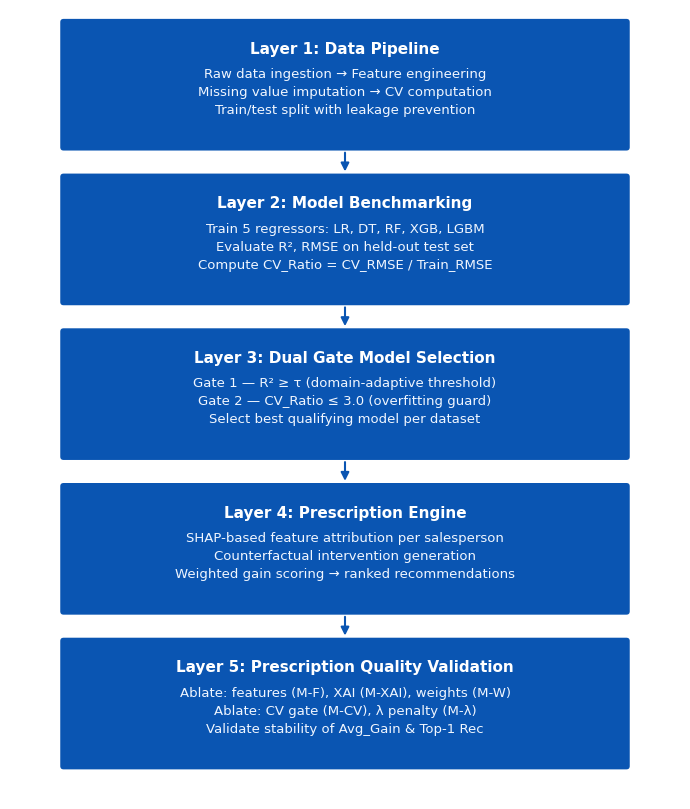

Flowchart saved with absolute minimal borders.


In [18]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

'''Flow chart of the framework — Compressed Border Profile'''
# FIX 1: Reduced figure height to 8.2 to completely shave off the empty padding
fig, ax = plt.subplots(figsize=(7, 8.2), facecolor='white')
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)  # Balanced maximum limit for the new height
ax.axis('off')
ax.set_facecolor('white')

layers = [
    ("Layer 1: Data Pipeline",
     "Raw data ingestion → Feature engineering\nMissing value imputation → CV computation\nTrain/test split with leakage prevention"),
    ("Layer 2: Model Benchmarking",
     "Train 5 regressors: LR, DT, RF, XGB, LGBM\nEvaluate R², RMSE on held-out test set\nCompute CV_Ratio = CV_RMSE / Train_RMSE"),
    ("Layer 3: Dual Gate Model Selection",
     "Gate 1 — R² ≥ τ (domain-adaptive threshold)\nGate 2 — CV_Ratio ≤ 3.0 (overfitting guard)\nSelect best qualifying model per dataset"),
    ("Layer 4: Prescription Engine",
     "SHAP-based feature attribution per salesperson\nCounterfactual intervention generation\nWeighted gain scoring → ranked recommendations"),
    ("Layer 5: Prescription Quality Validation",
     "Ablate: features (M-F), XAI (M-XAI), weights (M-W)\nAblate: CV gate (M-CV), λ penalty (M-λ)\nValidate stability of Avg_Gain & Top-1 Rec"),
]

box_height = 1.9
gap = 0.45
# FIX 2: Adjusted start_y to 11.8 to center the stack perfectly with no top padding
start_y = 11.8
box_x = 0.8
box_w = 8.4

for i, (title, content) in enumerate(layers):
    y_top = start_y - i * (box_height + gap)

    rect = FancyBboxPatch((box_x, y_top - box_height), box_w, box_height,
                          boxstyle="round,pad=0.05",
                          linewidth=0,
                          edgecolor='none',
                          facecolor='#0A55B2')
    ax.add_patch(rect)

    # Text rendering
    ax.text(box_x + box_w / 2, y_top - 0.28, title,
            ha='center', va='top', fontsize=11, fontweight='bold', color='white')

    ax.text(box_x + box_w / 2, y_top - 0.68, content,
            ha='center', va='top', fontsize=9.5, color='#F0F6FF',
            linespacing=1.5)

    # Arrow connections
    if i < len(layers) - 1:
        arrow_y_start = y_top - box_height
        arrow_y_end = arrow_y_start - gap
        ax.annotate("", xy=(5, arrow_y_end + 0.04),
                    xytext=(5, arrow_y_start - 0.04),
                    arrowprops=dict(arrowstyle="-|>", color='#0A55B2', lw=1.5, mutation_scale=12))

plt.tight_layout()
# pad=0 forces matplotlib to discard even the standard 0.1 inch default boundary
plt.savefig("Fig1_DIPPA_Flowchart.png", dpi=300, bbox_inches='tight', pad_inches=0, facecolor='white')
plt.show()
print("Flowchart saved with absolute minimal borders.")

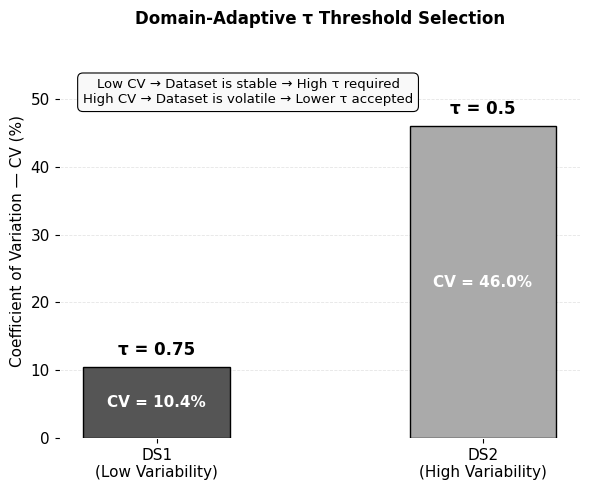

Fig2 cleanly compiled and updated.


In [5]:
import matplotlib.pyplot as plt

# Figure 2 — Domain-Adaptive τ Threshold Justification (Complete Labeled Profile)
fig, ax = plt.subplots(figsize=(6, 5), facecolor='white')

datasets = ['DS1\n(Low Variability)', 'DS2\n(High Variability)']
cv_values = [10.4, 46.0]
tau_values = [0.75, 0.50]
colors = ['#555555', '#AAAAAA']

# Generate stable structural bars
bars = ax.bar(datasets, cv_values, color=colors, edgecolor='black',
              linewidth=1.0, width=0.45, zorder=3)

# τ labels and values placed inside/above the bars cleanly
for bar, tau, cv in zip(bars, tau_values, cv_values):
    x = bar.get_x() + bar.get_width() / 2
    ax.text(x, bar.get_height() + 1.2, f'τ = {tau}',
            ha='center', va='bottom', fontsize=12, fontweight='bold', color='black')
    ax.text(x, bar.get_height() / 2, f'CV = {cv}%',
            ha='center', va='center', fontsize=11, fontweight='bold', color='white')

# Restoring comprehensive axis labels and ticks
ax.set_ylabel('Coefficient of Variation — CV (%)', fontsize=11, color='black')
ax.set_ylim(0, 58)
ax.set_yticks([0, 10, 20, 30, 40, 50])

# Configure background axis structure
ax.yaxis.grid(True, linestyle='--', linewidth=0.6, color='#CCCCCC', zorder=0)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)
ax.set_facecolor('white')

# Ensure tick marks and labels stand out cleanly in black
ax.tick_params(axis='both', which='major', labelsize=11, colors='black')

# Left-aligned framework context box with dark text override
ax.text(0.28, 51,
        "Low CV → Dataset is stable → High τ required\nHigh CV → Dataset is volatile → Lower τ accepted",
        fontsize=9.5, ha='center', va='center', color='black',
        bbox=dict(boxstyle='round,pad=0.4', edgecolor='black', facecolor='#F9F9F9', linewidth=0.8))

# Main Graphic Title Header
ax.set_title("Domain-Adaptive τ Threshold Selection", fontsize=12, fontweight='bold', pad=15, color='black')

plt.tight_layout()
# Shave off all raw external bounding box pads dynamically
plt.savefig("Fig2_Tau_Threshold.png", dpi=300, bbox_inches='tight', pad_inches=0.02, facecolor='white')
plt.show()
print("Fig2 cleanly compiled and updated.")

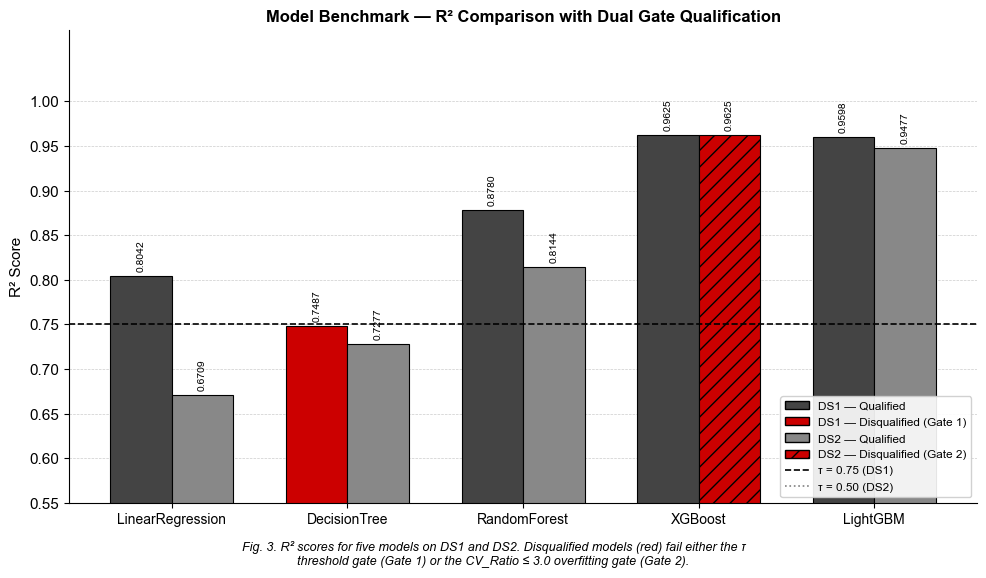

Fig3 saved.


In [17]:
#Figure 3 — Model Benchmark Comparison
fig, ax = plt.subplots(figsize=(10, 5.5))

models = ['LinearRegression', 'DecisionTree', 'RandomForest', 'XGBoost', 'LightGBM']
ds1_r2 = [0.8042, 0.7487, 0.8780, 0.9625, 0.9598]
ds2_r2 = [0.6709, 0.7277, 0.8144, 0.9625, 0.9477]

# Qualification status
# DS1: DT fails (R²=0.7487 < 0.75). Others pass.
# DS2: XGB fails CV_Ratio gate (not R² gate). All others pass.
ds1_fail = [False, True, False, False, False]   # DT disqualified on DS1
ds2_fail = [False, False, False, True, False]   # XGB disqualified on DS2

x = np.arange(len(models))
width = 0.35

def bar_color(fail, is_ds2=False):
    return '#CC0000' if fail else ('#444444' if not is_ds2 else '#888888')

for i, (r2_1, r2_2, f1, f2) in enumerate(zip(ds1_r2, ds2_r2, ds1_fail, ds2_fail)):
    b1 = ax.bar(x[i] - width/2, r2_1, width,
                color=bar_color(f1), edgecolor='black', linewidth=0.8)
    b2 = ax.bar(x[i] + width/2, r2_2, width,
                color=bar_color(f2, True), edgecolor='black', linewidth=0.8,
                hatch='//' if f2 else '')
    ax.text(x[i] - width/2, r2_1 + 0.005, f'{r2_1:.4f}',
            ha='center', va='bottom', fontsize=7.5, rotation=90)
    ax.text(x[i] + width/2, r2_2 + 0.005, f'{r2_2:.4f}',
            ha='center', va='bottom', fontsize=7.5, rotation=90)

# Threshold lines
ax.axhline(0.75, color='black', linewidth=1.2, linestyle='--', label='τ=0.75 (DS1)')
ax.axhline(0.50, color='gray', linewidth=1.2, linestyle=':', label='τ=0.50 (DS2)')

ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=10)
ax.set_ylabel('R² Score', fontsize=11)
ax.set_ylim(0.55, 1.08)
ax.set_yticks(np.arange(0.55, 1.05, 0.05))
ax.yaxis.grid(True, linestyle='--', linewidth=0.5, color='#CCCCCC')
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title("Model Benchmark — R² Comparison with Dual Gate Qualification", fontsize=12, fontweight='bold')

legend_elements = [
    mpatches.Patch(facecolor='#444444', edgecolor='black', label='DS1 — Qualified'),
    mpatches.Patch(facecolor='#CC0000', edgecolor='black', label='DS1 — Disqualified (Gate 1)'),
    mpatches.Patch(facecolor='#888888', edgecolor='black', label='DS2 — Qualified'),
    mpatches.Patch(facecolor='#CC0000', edgecolor='black', hatch='//', label='DS2 — Disqualified (Gate 2)'),
    plt.Line2D([0],[0], color='black', lw=1.2, linestyle='--', label='τ = 0.75 (DS1)'),
    plt.Line2D([0],[0], color='gray', lw=1.2, linestyle=':', label='τ = 0.50 (DS2)'),
]
ax.legend(handles=legend_elements, fontsize=8.5, loc='lower right', framealpha=0.9)

fig.text(0.5, -0.04,
         "Fig. 3. R² scores for five models on DS1 and DS2. Disqualified models (red) fail either the τ\n"
         "threshold gate (Gate 1) or the CV_Ratio ≤ 3.0 overfitting gate (Gate 2).",
         ha='center', fontsize=9, style='italic')

plt.tight_layout()
plt.savefig("Fig3_Model_Benchmark.png", dpi=300, bbox_inches='tight')
plt.show()
print("Fig3 saved.")

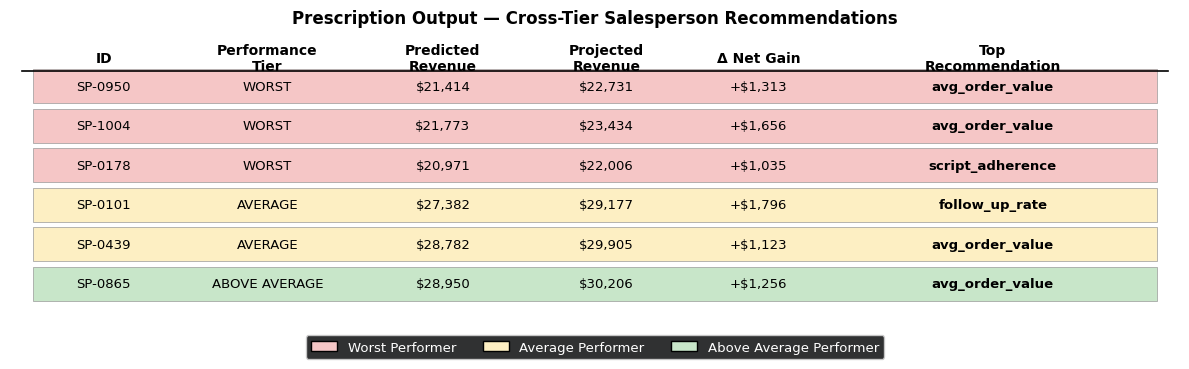

Bottom border completely cropped.


In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Figure 4 — Prescription Output Table (Trimmed Bottom Border)
# FIX 1: Reduced figure height from 5 to 3.8 to eliminate dead vertical space
fig, ax = plt.subplots(figsize=(12, 3.8), facecolor='white')
ax.axis('off')
ax.set_facecolor('white')

columns = ['ID', 'Performance\nTier', 'Predicted\nRevenue', 'Projected\nRevenue',
           'Δ Net Gain', 'Top\nRecommendation']

data = [
    ['SP-0950', 'WORST',         '$21,414', '$22,731', '+$1,313', 'avg_order_value'],
    ['SP-1004', 'WORST',         '$21,773', '$23,434', '+$1,656', 'avg_order_value'],
    ['SP-0178', 'WORST',         '$20,971', '$22,006', '+$1,035', 'script_adherence'],
    ['SP-0101', 'AVERAGE',       '$27,382', '$29,177', '+$1,796', 'follow_up_rate'],
    ['SP-0439', 'AVERAGE',       '$28,782', '$29,905', '+$1,123', 'avg_order_value'],
    ['SP-0865', 'ABOVE AVERAGE', '$28,950', '$30,206', '+$1,256', 'avg_order_value'],
]

tier_colors = {
    'WORST':         '#F5C6C6',
    'AVERAGE':       '#FDEFC3',
    'ABOVE AVERAGE': '#C8E6C9',
}

col_widths = [0.12, 0.16, 0.14, 0.14, 0.12, 0.28]
col_positions = [0.02]
for w in col_widths[:-1]:
    col_positions.append(col_positions[-1] + w)

# FIX 2: Expanded row heights dynamically to fill the newly compressed canvas bounds
row_h = 0.14
header_y = 0.95

# Header
for col_label, xpos, cw in zip(columns, col_positions, col_widths):
    ax.text(xpos + cw/2, header_y, col_label,
            ha='center', va='center', fontsize=10, fontweight='bold', color='black',
            transform=ax.transAxes)

ax.axhline(y=header_y - 0.045, xmin=0.01, xmax=0.99,
           color='black', linewidth=1.2)

# Rows
for r_idx, row in enumerate(data):
    tier = row[1]
    bg = tier_colors[tier]
    y_center = header_y - 0.10 - r_idx * row_h

    rect = mpatches.FancyBboxPatch((0.02, y_center - row_h/2 + 0.01), 0.96, row_h - 0.02,
                                    boxstyle="square,pad=0", linewidth=0.5,
                                    edgecolor='#999999', facecolor=bg,
                                    transform=ax.transAxes)
    ax.add_patch(rect)

    for c_idx, (cell, xpos, cw) in enumerate(zip(row, col_positions, col_widths)):
        weight = 'bold' if c_idx == 5 else 'normal'
        ax.text(xpos + cw/2, y_center, cell,
                ha='center', va='center', fontsize=9.5, fontweight=weight, color='black',
                transform=ax.transAxes)

# Legend (Safely tucked right below the final row boundary)
legend_patches = [
    mpatches.Patch(facecolor='#F5C6C6', edgecolor='black', label='Worst Performer'),
    mpatches.Patch(facecolor='#FDEFC3', edgecolor='black', label='Average Performer'),
    mpatches.Patch(facecolor='#C8E6C9', edgecolor='black', label='Above Average Performer'),
]
ax.legend(handles=legend_patches, loc='upper center', bbox_to_anchor=(0.5, -0.01),
          ncol=3, fontsize=9.5, framealpha=0.9, edgecolor='#CCCCCC')

ax.set_title("Prescription Output — Cross-Tier Salesperson Recommendations",
             fontsize=12, fontweight='bold', pad=15, x=0.5, color='black')

plt.tight_layout()
# FIX 3: Explicitly shave off edge boundaries with pad_inches
plt.savefig("Fig4_Prescription_Table.png", dpi=300, bbox_inches='tight', pad_inches=0.02, facecolor='white')
plt.show()
print("Bottom border completely cropped.")

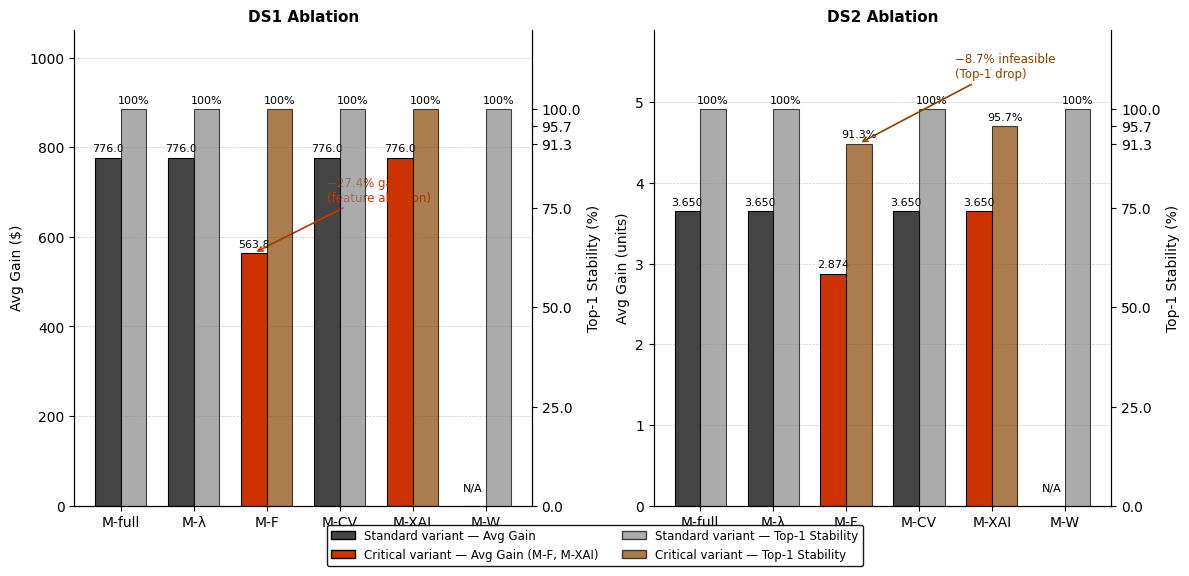

Fig5 saved cleanly with no caption.


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

# Force pure white mode
plt.style.use('default')

# Figure 5 — Ablation Study Results
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=False, facecolor='white')

variants = ['M-full', 'M-λ', 'M-F', 'M-CV', 'M-XAI', 'M-W']
x = np.arange(len(variants))
width = 0.35

# DS1 data
ds1_gain   = [775.96, 775.96, 563.76, 775.96, 775.96, None]
ds1_top1   = [100, 100, 100, 100, 100, 100]

# DS2 data
ds2_gain   = [3.650, 3.650, 2.874, 3.650, 3.650, None]
ds2_top1   = [100, 100, 91.3, 100, 95.7, 100]

highlight_idx = [2, 4]  # M-F (index 2), M-XAI (index 4)

def plot_ablation(ax, gains, top1s, title, ylabel_gain, max_gain):
    ax.set_facecolor('white')
    ax2 = ax.twinx()

    gain_colors = []
    top1_colors = []
    for i in range(len(variants)):
        if i in highlight_idx:
            gain_colors.append('#CC3300')
            top1_colors.append('#884400')
        else:
            gain_colors.append('#444444')
            top1_colors.append('#888888')

    for i, (g, t, gc, tc) in enumerate(zip(gains, top1s, gain_colors, top1_colors)):
        xpos = x[i]
        if g is not None:
            b1 = ax.bar(xpos - width/2, g, width, color=gc, edgecolor='black', linewidth=0.8)
            ax.text(xpos - width/2, g + max_gain*0.01, f'{g:.3f}' if g < 10 else f'{g:.1f}',
                    ha='center', va='bottom', fontsize=8, color='black')
        else:
            ax.bar(xpos - width/2, 0, width, color='#CCCCCC', edgecolor='black',
                   linewidth=0.8, hatch='xxx')
            ax.text(xpos - width/2, max_gain*0.03, 'N/A', ha='center', va='bottom', fontsize=8, color='black')

        b2 = ax2.bar(xpos + width/2, t, width, color=tc, edgecolor='black',
                     linewidth=0.8, alpha=0.7)
        ax2.text(xpos + width/2, t + 1.0, f'{t}%', ha='center', va='bottom', fontsize=8, color='black')

    ax.set_xticks(x)
    ax.set_xticklabels(variants, fontsize=10, color='black')
    ax.set_ylabel(ylabel_gain, fontsize=10, color='black')
    ax2.set_ylabel('Top-1 Stability (%)', fontsize=10, color='black')
    ax2.set_ylim(0, 120)
    ax2.set_yticks([0, 25, 50, 75, 91.3, 95.7, 100])

    # Keep axis ticks and spines black
    ax.tick_params(axis='both', colors='black')
    ax2.tick_params(axis='both', colors='black')
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
    for spine in ax2.spines.values():
        spine.set_edgecolor('black')

    ax.set_ylim(0, max_gain * 1.18)
    ax.yaxis.grid(True, linestyle='--', linewidth=0.5, color='#CCCCCC')
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax2.spines['top'].set_visible(False)
    ax.set_title(title, fontsize=11, fontweight='bold', color='black')
    return ax2

ax2_ds1 = plot_ablation(axes[0], ds1_gain, ds1_top1,
                         "DS1 Ablation", "Avg Gain ($)", 900)
ax2_ds2 = plot_ablation(axes[1], ds2_gain, ds2_top1,
                         "DS2 Ablation", "Avg Gain (units)", 5)

# Annotations — M-F
axes[0].annotate("−27.4% gain\n(feature ablation)",
                 xy=(2 - width/2, 563.76), xytext=(2 - width/2 + 1.0, 680),
                 fontsize=8.5, color='#CC3300',
                 arrowprops=dict(arrowstyle='->', color='#CC3300', lw=1.2))

ax2_ds2.annotate("−8.7% infeasible\n(Top-1 drop)",
                 xy=(2 + width/2, 91.3), xytext=(3.5, 108),
                 fontsize=8.5, color='#884400',
                 arrowprops=dict(arrowstyle='->', color='#884400', lw=1.2))

legend_els = [
    mpatches.Patch(facecolor='#444444', edgecolor='black', label='Standard variant — Avg Gain'),
    mpatches.Patch(facecolor='#CC3300', edgecolor='black', label='Critical variant — Avg Gain (M-F, M-XAI)'),
    mpatches.Patch(facecolor='#888888', edgecolor='black', alpha=0.7, label='Standard variant — Top-1 Stability'),
    mpatches.Patch(facecolor='#884400', edgecolor='black', alpha=0.7, label='Critical variant — Top-1 Stability'),
]
fig.legend(handles=legend_els, loc='lower center', ncol=2, fontsize=8.5,
           bbox_to_anchor=(0.5, -0.05), framealpha=0.9, facecolor='white', edgecolor='black', labelcolor='black')

# Caption removed completely

plt.tight_layout()
# Adjusted padding slightly so the legend doesn't get chopped off at the bottom
plt.savefig("Fig5_Ablation_Study.png", dpi=300, bbox_inches='tight', pad_inches=0.05, facecolor='white')
plt.show()
print("Fig5 saved cleanly with no caption.")

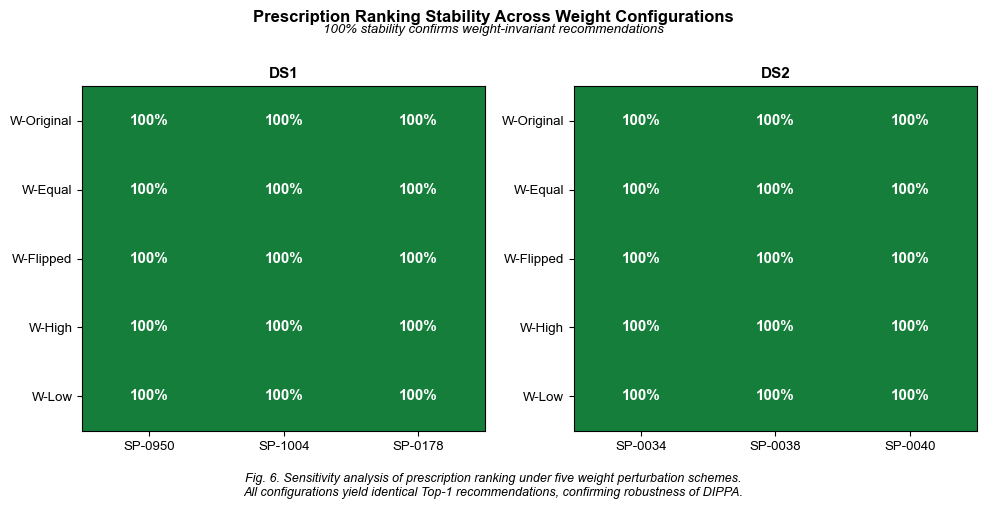

Fig6 saved.


In [22]:
#Figure 6 — Sensitivity Analysis Heatmap
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

weights = ['W-Original', 'W-Equal', 'W-Flipped', 'W-High', 'W-Low']
ds1_persons = ['SP-0950', 'SP-1004', 'SP-0178']
ds2_persons = ['SP-0034', 'SP-0038', 'SP-0040']

data_matrix = np.full((5, 3), 100.0)

from matplotlib.colors import LinearSegmentedColormap
green_cmap = LinearSegmentedColormap.from_list('solid_green', ['#4CAF50', '#4CAF50'])

for ax, persons, title_suffix in zip(axes, [ds1_persons, ds2_persons], ['DS1', 'DS2']):
    im = ax.imshow(data_matrix, cmap='Greens', vmin=80, vmax=105, aspect='auto')

    ax.set_xticks(np.arange(3))
    ax.set_yticks(np.arange(5))
    ax.set_xticklabels(persons, fontsize=9.5)
    ax.set_yticklabels(weights, fontsize=9.5)

    for i in range(5):
        for j in range(3):
            ax.text(j, i, '100%', ha='center', va='center',
                    fontsize=11, fontweight='bold', color='white')

    ax.set_title(title_suffix, fontsize=11, fontweight='bold')
    ax.tick_params(top=False, bottom=True, labeltop=False, labelbottom=True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)

fig.suptitle("Prescription Ranking Stability Across Weight Configurations",
             fontsize=12, fontweight='bold', y=1.02)
fig.text(0.5, 0.97,
         "100% stability confirms weight-invariant recommendations",
         ha='center', fontsize=9.5, style='italic')

fig.text(0.5, -0.06,
         "Fig. 6. Sensitivity analysis of prescription ranking under five weight perturbation schemes.\n"
         "All configurations yield identical Top-1 recommendations, confirming robustness of DIPPA.",
         ha='center', fontsize=9, style='italic')

plt.tight_layout()
plt.savefig("Fig6_Sensitivity_Heatmap.png", dpi=300, bbox_inches='tight')
plt.show()
print("Fig6 saved.")

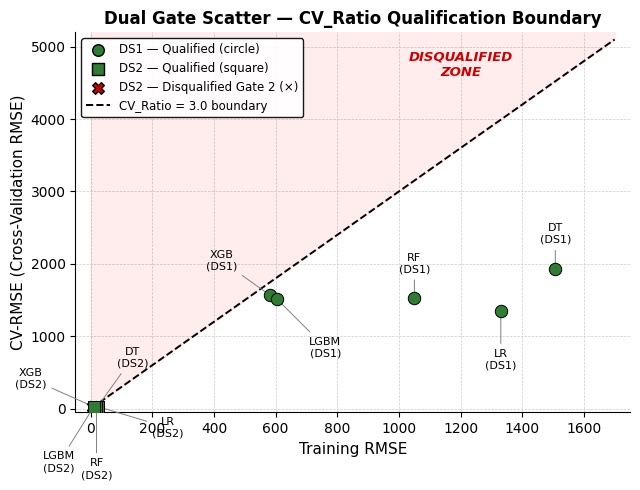

Saved! All text labels are now cleanly separated with pointer lines.


In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Force pure white mode
plt.style.use('default')
fig, ax = plt.subplots(figsize=(6.5, 5), facecolor='white')
ax.set_facecolor('white')

ds1_points = {
    'LR':  (1330.64, 1347.07),
    'DT':  (1507.53, 1931.81),
    'RF':  (1050.26, 1524.84),
    'XGB': (581.98,  1564.11),
    'LGBM':(603.24,  1517.11),
}
ds2_points = {
    'LR':  (24.53, 24.87),
    'DT':  (22.31, 27.99),
    'RF':  (18.42, 25.55),
    'XGB': (8.28,  26.93),
    'LGBM':(9.78,  26.33),
}

# CV_Ratio boundary
x_line = np.array([0, 1700])
y_line = 3 * x_line
ax.plot(x_line, y_line, color='black', linewidth=1.4, linestyle='--', label='CV_Ratio = 3.0 boundary')

# Shaded disqualified zone
ax.fill_between(x_line, y_line, 5500, color='#FF0000', alpha=0.07)
ax.text(1200, 4600, 'DISQUALIFIED\nZONE', color='#CC0000', fontsize=9.5,
        fontstyle='italic', ha='center', fontweight='bold')

ds2_fail = {'XGB'}

# FIX 1: Explicit pixel offsets for DS1 to prevent DT, XGB, and LGBM from overlapping markers
ds1_offsets = {
    'LR':   (0, -35),   # Pushed down
    'DT':   (0, 25),    # Pushed safely up
    'RF':   (0, 25),    # Pushed up
    'XGB':  (-35, 25),  # Pushed top-left away from the marker
    'LGBM': (35, -35),  # Pushed bottom-right to clear XGB entirely
}

# FIX 2: "Starburst" pixel offsets for the clustered DS2 group at the origin
ds2_offsets = {
    'XGB':  (-45, 20),  # Red X pushed far left
    'LGBM': (-25, -40), # Pushed bottom-left
    'RF':   (0, -45),   # Pushed straight down
    'DT':   (25, 35),   # Pushed top-right
    'LR':   (50, -15),  # Pushed far right
}

# Plot DS1 Group
for name, (tx, ty) in ds1_points.items():
    ax.scatter(tx, ty, color='#2E7D32', s=80, zorder=5, edgecolors='black', linewidths=0.7)

    # Use textcoords='offset points' to lock the distance from the dot
    ax.annotate(f'{name}\n(DS1)', xy=(tx, ty), xytext=ds1_offsets[name], textcoords='offset points',
                fontsize=8, ha='center', va='center', color='black',
                arrowprops=dict(arrowstyle='-', color='gray', lw=0.7))

# Plot DS2 Group
for name, (tx, ty) in ds2_points.items():
    fail = name in ds2_fail
    color = '#CC0000' if fail else '#2E7D32'
    marker = 'X' if fail else 's'

    ax.scatter(tx, ty, color=color, s=80, zorder=5, marker=marker, edgecolors='black', linewidths=0.7)

    # Use textcoords='offset points' to spread out the clustered text
    ax.annotate(f'{name}\n(DS2)', xy=(tx, ty), xytext=ds2_offsets[name], textcoords='offset points',
                fontsize=8, ha='center', va='center', color='black',
                arrowprops=dict(arrowstyle='-', color='gray', lw=0.7))

# Layout Cosmetics
ax.set_xlabel('Training RMSE', fontsize=11, color='black')
ax.set_ylabel('CV-RMSE (Cross-Validation RMSE)', fontsize=11, color='black')
ax.set_title("Dual Gate Scatter — CV_Ratio Qualification Boundary", fontsize=12, fontweight='bold', color='black')
ax.set_xlim(-50, 1750)
ax.set_ylim(-50, 5200)

ax.yaxis.grid(True, linestyle='--', linewidth=0.5, color='#CCCCCC')
ax.xaxis.grid(True, linestyle='--', linewidth=0.5, color='#CCCCCC')
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_edgecolor('black')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', colors='black')

legend_els = [
    plt.scatter([], [], color='#2E7D32', marker='o', s=70, edgecolors='black', label='DS1 — Qualified (circle)'),
    plt.scatter([], [], color='#2E7D32', marker='s', s=70, edgecolors='black', label='DS2 — Qualified (square)'),
    plt.scatter([], [], color='#CC0000', marker='X', s=70, edgecolors='black', label='DS2 — Disqualified Gate 2 (×)'),
    plt.Line2D([0],[0], color='black', lw=1.4, linestyle='--', label='CV_Ratio = 3.0 boundary'),
]
ax.legend(handles=legend_els, fontsize=8.5, loc='upper left',
          framealpha=0.9, facecolor='white', edgecolor='black', labelcolor='black')

plt.tight_layout()
plt.savefig("Fig7_DualGate_Scatter_CleanText.png", dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
plt.show()
print("Saved! All text labels are now cleanly separated with pointer lines.")

In [5]:
import matplotlib.pyplot as plt

# Force pure white background mode
plt.style.use('default')

# ---------------------------------------------------------
# DATA PREPARATION (Cleaned and rounded for presentation)
# ---------------------------------------------------------
columns = ['Variant', 'R²', 'RMSE', 'CV-RMSE', 'Avg Gain', 'Avg Effort', 'Feasibility', 'Top-1 Stable']

data_ds1 = [
    ['M-full ★', '0.9596', '604.71', '1515.73', '775.96', '1.08', '100.0%', '100.0%'],
    ['M-λ',      '0.9596', '604.71', '1515.73', '775.96', '0.00', '100.0%', '100.0%'],
    ['M-F',      '0.9596', '604.71', '1515.73', '563.76', '0.79', '100.0%', '100.0%'],
    ['M-CV',     '0.9596', '604.71', 'N/A',     '775.96', '1.08', '100.0%', '100.0%'],
    ['M-XAI',    '0.9596', '604.71', '1515.73', '775.96', '0.65', '100.0%', '100.0%'],
    ['M-W',      'N/A',    'N/A',    'N/A',     'N/A',    'N/A',  '100.0%', '100.0%']
]

data_ds2 = [
    ['M-full ★', '0.9485', '9.70', '26.22', '3.65', '0.03', '100.0%', '100.0%'],
    ['M-λ',      '0.9485', '9.70', '26.22', '3.65', '0.00', '100.0%', '100.0%'],
    ['M-F',      '0.9485', '9.70', '26.22', '2.87', '0.05', '91.3%',  '91.3%'],
    ['M-CV',     '0.9485', '9.70', 'N/A',   '3.65', '0.03', '100.0%', '100.0%'],
    ['M-XAI',    '0.9485', '9.70', '26.22', '3.65', '0.04', '100.0%', '95.7%'],
    ['M-W',      'N/A',    'N/A',  'N/A',   'N/A',  'N/A',  '100.0%', '100.0%']
]

# ---------------------------------------------------------
# TABLE GENERATION FUNCTION (IEEE-Style Format)
# ---------------------------------------------------------
def generate_academic_table(data, title, filename):
    fig, ax = plt.subplots(figsize=(9, 3.5), facecolor='white')
    ax.axis('off')
    ax.set_facecolor('white')

    # Add the title above the table
    ax.text(0.5, 0.92, title, ha='center', va='center',
            fontsize=12, fontweight='bold', color='black', transform=ax.transAxes)

    # Create the table
    table = ax.table(cellText=data, colLabels=columns, cellLoc='center', loc='center')

    # Style the table
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.8)  # Expand row height slightly for breathability

    for (row, col), cell in table.get_celld().items():
        cell.set_text_props(color='black')

        # Remove all borders by default for a clean look
        cell.set_linewidth(0)

        if row == 0:
            # Header styling
            cell.set_text_props(fontweight='bold')
            # Add top and bottom border to the header row
            cell.set_edgecolor('black')
            cell.set_linewidth(1.2)
            cell.visible_edges = 'TB'
        elif row == len(data):
            # Add bottom border to the final row of data
            cell.set_edgecolor('black')
            cell.set_linewidth(1.2)
            cell.visible_edges = 'B'

        # Highlight specific critical drops (M-F and M-XAI) with bold text
        if row == 3 and col in [4, 6, 7]: # M-F row
            cell.set_text_props(fontweight='bold', color='#D32F2F')
        if row == 5 and col == 7:         # M-XAI row (Top-1 drop)
            cell.set_text_props(fontweight='bold', color='#D32F2F')

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight', pad_inches=0.05, facecolor='white')
    plt.close()
    print(f"Saved cleanly: {filename}")

# ---------------------------------------------------------
# EXECUTE GENERATION
# ---------------------------------------------------------
generate_academic_table(data_ds1, "TABLE I: ABLATION STUDY — DS1 (B2C RETAIL)", "Table1_Ablation_DS1.png")
generate_academic_table(data_ds2, "TABLE II: ABLATION STUDY — DS2 (B2B ACCOUNT EXECUTIVES)", "Table2_Ablation_DS2.png")


Saved cleanly: Table1_Ablation_DS1.png
Saved cleanly: Table2_Ablation_DS2.png


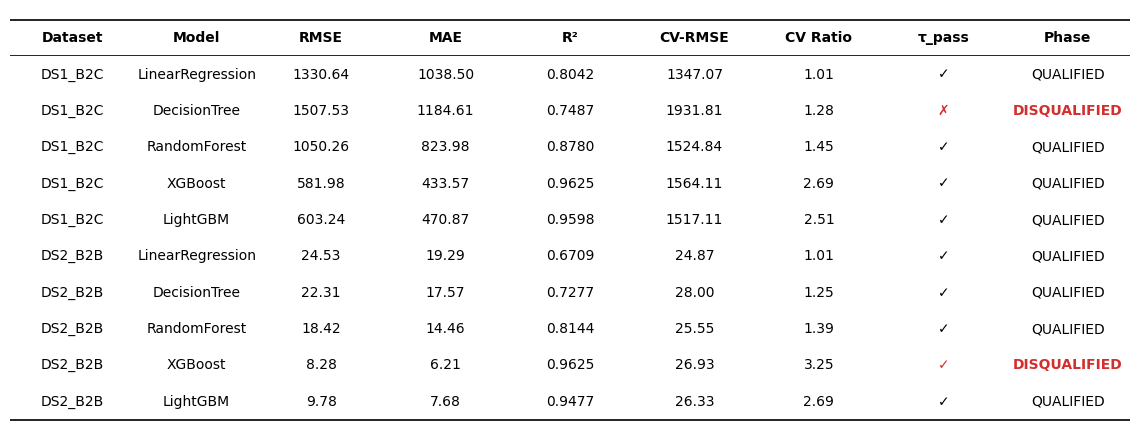

Table generated cleanly without overlap and with full wording.


In [7]:
import matplotlib.pyplot as plt

# Force pure white background mode
plt.style.use('default')

columns = ['Dataset', 'Model', 'RMSE', 'MAE', 'R²', 'CV-RMSE', 'CV Ratio', 'τ_pass', 'Phase']

# Expanded "QUALIFIED" and "DISQUALIFIED"
data = [
    ['DS1_B2C', 'LinearRegression', '1330.64', '1038.50', '0.8042', '1347.07', '1.01', '✓', 'QUALIFIED'],
    ['DS1_B2C', 'DecisionTree',     '1507.53', '1184.61', '0.7487', '1931.81', '1.28', '✗', 'DISQUALIFIED'],
    ['DS1_B2C', 'RandomForest',     '1050.26', '823.98',  '0.8780', '1524.84', '1.45', '✓', 'QUALIFIED'],
    ['DS1_B2C', 'XGBoost',          '581.98',  '433.57',  '0.9625', '1564.11', '2.69', '✓', 'QUALIFIED'],
    ['DS1_B2C', 'LightGBM',         '603.24',  '470.87',  '0.9598', '1517.11', '2.51', '✓', 'QUALIFIED'],
    ['DS2_B2B', 'LinearRegression', '24.53',   '19.29',   '0.6709', '24.87',   '1.01', '✓', 'QUALIFIED'],
    ['DS2_B2B', 'DecisionTree',     '22.31',   '17.57',   '0.7277', '28.00',   '1.25', '✓', 'QUALIFIED'],
    ['DS2_B2B', 'RandomForest',     '18.42',   '14.46',   '0.8144', '25.55',   '1.39', '✓', 'QUALIFIED'],
    ['DS2_B2B', 'XGBoost',          '8.28',    '6.21',    '0.9625', '26.93',   '3.25', '✓', 'DISQUALIFIED'],
    ['DS2_B2B', 'LightGBM',         '9.78',    '7.68',    '0.9477', '26.33',   '2.69', '✓', 'QUALIFIED']
]

# Expanded width slightly to fit the full words
fig, ax = plt.subplots(figsize=(11.5, 4.5), facecolor='white')
ax.axis('off')
ax.set_facecolor('white')

# REMOVED the overlapping title block completely

# Create the table
table = ax.table(cellText=data, colLabels=columns, cellLoc='center', loc='center')

# Style the table to academic standards
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.8)

for (row, col), cell in table.get_celld().items():
    cell.set_text_props(color='black')
    cell.set_linewidth(0) # Remove internal gridlines

    if row == 0:
        # Header formatting
        cell.set_text_props(fontweight='bold')
        cell.set_edgecolor('black')
        cell.set_linewidth(1.2)
        cell.visible_edges = 'TB'
    elif row == len(data):
        # Bottom border formatting
        cell.set_edgecolor('black')
        cell.set_linewidth(1.2)
        cell.visible_edges = 'B'

    # Highlight the disqualified models in a subtle red (columns 7 and 8)
    if row == 2 and col in [7, 8]: # DS1 DecisionTree
        cell.set_text_props(fontweight='bold', color='#D32F2F')
    if row == 9 and col in [7, 8]: # DS2 XGBoost
        cell.set_text_props(fontweight='bold', color='#D32F2F')

plt.tight_layout()
plt.savefig("Table3_Model_Evaluation_Clean.png", dpi=300, bbox_inches='tight', pad_inches=0.05, facecolor='white')
plt.show()
print("Table generated cleanly without overlap and with full wording.")